# 01 - Exploratory Data Analysis

Inspect event types, visitor activity, and coverage before defining the return cohort.

In [1]:
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt


## Loading Data

In [2]:
project_dir = Path.cwd()
if not (project_dir / "data" / "raw" / "events.csv").exists():
    project_dir = project_dir.parent
DATA_PATH = project_dir / "data" / "raw" / "events.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError("Dataset not found. Check the data/raw folder.")

con = duckdb.connect(":memory:")
con.execute("SET TimeZone = 'UTC'")

con.execute("""
    CREATE TABLE events AS
    SELECT
        visitorid AS user_id,
        to_timestamp(CAST(timestamp AS BIGINT) / 1000.0) AS event_timestamp,
        event AS event_type,
        itemid AS item_id
    FROM read_csv_auto(?)
""", [str(DATA_PATH)])

print("Data loaded successfully.")


Data loaded successfully.


## Data schema

In [3]:
con.execute("DESCRIBE events").df()

,column_name,column_type,null,key,default,extra
0,user_id,BIGINT,YES,None,None,None
1,event_timestamp,TIMESTAMP WITH TIME ZONE,YES,None,None,None
2,event_type,VARCHAR,YES,None,None,None
3,item_id,BIGINT,YES,None,None,None


## Event mix

In [4]:
event_counts = con.execute("""
    SELECT
        event_type,
        COUNT(*) AS event_count
    FROM events
    GROUP BY event_type
    ORDER BY event_count DESC
""").df()

event_counts["percentage"] = (
    event_counts["event_count"] / event_counts["event_count"].sum() * 100
)

event_counts

,event_type,event_count,percentage
0,view,2664312,96.669607
1,addtocart,69332,2.515583
2,transaction,22457,0.814810


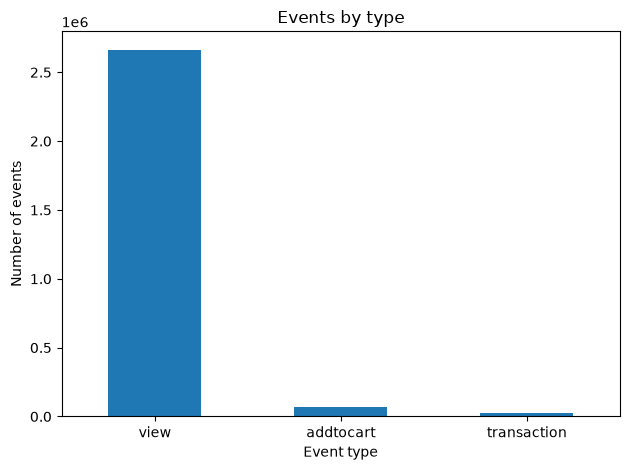

In [5]:
event_counts.plot(
    x="event_type",
    y="event_count",
    kind="bar",
    legend=False,
    xlabel="Event type",
    ylabel="Number of events",
    title="Events by type",
    rot=0
)
plt.tight_layout()
plt.show()

The labels are `view`, `addtocart`, and `transaction`: product views, cart additions, and recorded purchases. Views dominate, so raw event counts are not a conversion rate.

## Activity per user

In [6]:
user_activity = con.execute("""
    SELECT user_id, COUNT(*) AS event_count
    FROM events
    GROUP BY user_id
""").df()

user_activity["event_count"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]
)

count    1.407580e+06
mean     1.958042e+00
std      1.258049e+01
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      2.000000e+00
90%      3.000000e+00
99%      1.300000e+01
max      7.757000e+03
Name: event_count, dtype: float64

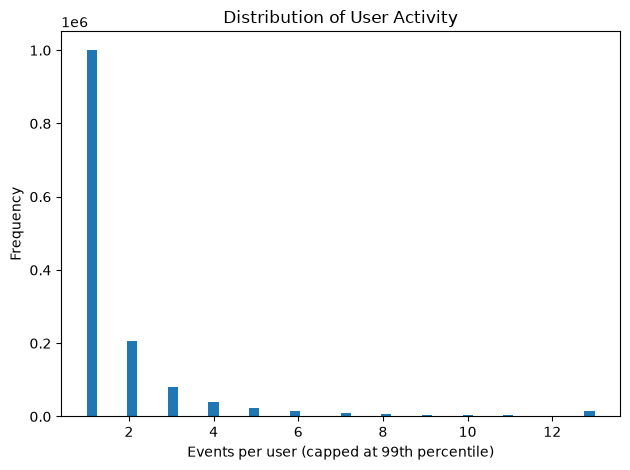

In [7]:
user_activity["event_count"].clip(
    upper=user_activity["event_count"].quantile(0.99)
).plot(
    kind="hist",
    bins=50,
    xlabel="Events per user (capped at 99th percentile)",
    title="Distribution of User Activity"
)

plt.tight_layout()
plt.show()

Most visitors have very short histories in this log. The long upper tail means a small number of visitors are much more active, so the mean is less representative than the median.

## Activity over time

In [8]:
daily_activity = con.execute("""
    SELECT
        CAST(event_timestamp AS DATE) AS event_date,
        COUNT(*) AS event_count,
        COUNT(DISTINCT user_id) AS active_users
    FROM events
    GROUP BY event_date
    ORDER BY event_date
""").df()

daily_activity.head()

,event_date,event_count,active_users
0,2015-05-03,13683,7865
1,2015-05-04,19414,11019
2,2015-05-05,23015,13084
3,2015-05-06,23920,13687
4,2015-05-07,23164,13086


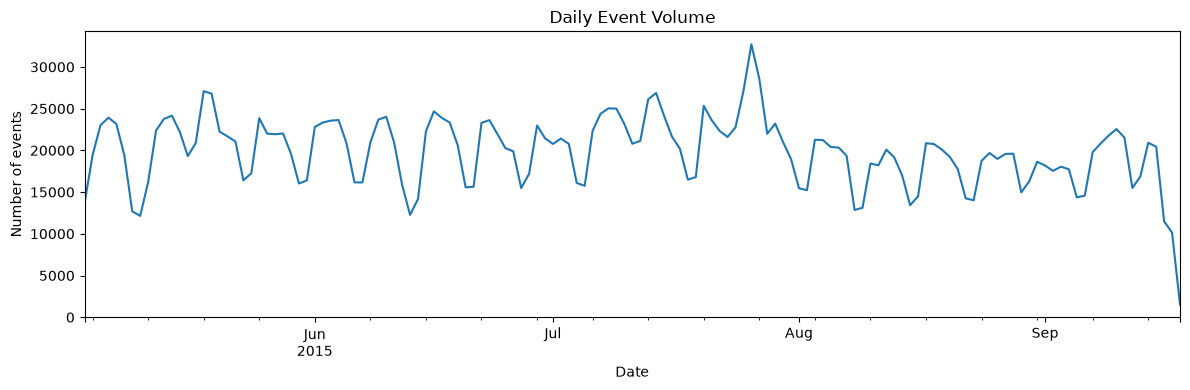

In [9]:
daily_activity.plot(
    x="event_date",
    y="event_count",
    legend=False,
    xlabel="Date",
    ylabel="Number of events",
    title="Daily Event Volume",
    figsize=(12, 4)
)

plt.tight_layout()
plt.show()

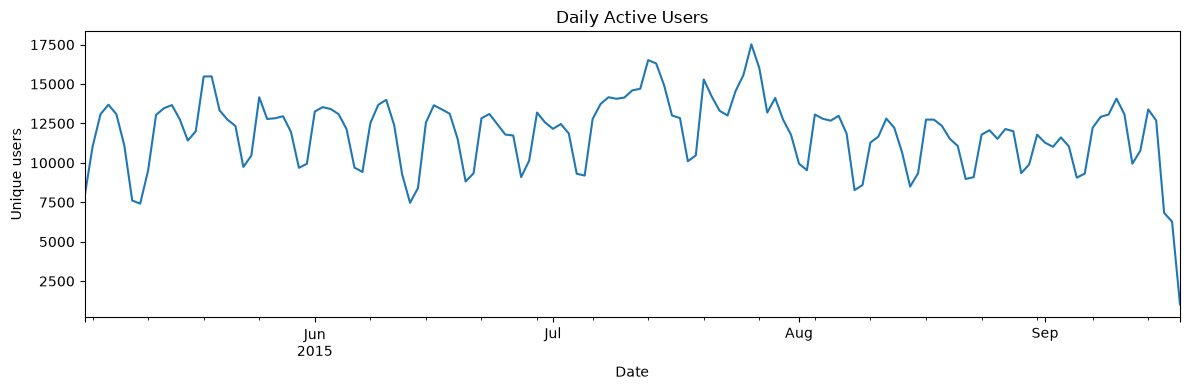

In [10]:
daily_activity.plot(
    x="event_date",
    y="active_users",
    legend=False,
    xlabel="Date",
    ylabel="Unique users",
    title="Daily Active Users",
    figsize=(12, 4)
)

plt.tight_layout()
plt.show()

The daily charts show recorded activity over time. Daily active users have at least one event that day; this count alone does not measure repeat retention.

## Data quality

In [11]:
con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(*) FILTER (WHERE user_id IS NULL) AS missing_user_id,
        COUNT(*) FILTER (WHERE event_timestamp IS NULL) AS missing_timestamp,
        COUNT(*) FILTER (WHERE event_type IS NULL) AS missing_event_type,
        COUNT(*) FILTER (WHERE item_id IS NULL) AS missing_item_id
    FROM events
""").df()

,total_rows,missing_user_id,missing_timestamp,missing_event_type,missing_item_id
0,2756101,0,0,0,0


In [12]:
con.execute("""
    SELECT
        COUNT(*) AS duplicate_groups,
        SUM(n - 1) AS extra_rows
    FROM (
        SELECT COUNT(*) AS n
        FROM events
        GROUP BY user_id, event_timestamp, event_type, item_id
        HAVING COUNT(*) > 1
    )
""").df()

,duplicate_groups,extra_rows
0,458,460.0


In [13]:
con.execute("""
    SELECT
        COUNT(*) FILTER (WHERE event_timestamp > CURRENT_TIMESTAMP) AS future_events
    FROM events
""").df()

,future_events
0,0


I kept the 460 rows that match on visitor, timestamp, event, and item; identical fields alone do not show whether a row is a duplicate.

## Observation window

In [14]:
con.execute("""
    SELECT
        MIN(event_timestamp) AS first_event,
        MAX(event_timestamp) AS last_event,
        DATE_DIFF(
            'day',
            CAST(MIN(event_timestamp) AS DATE),
            CAST(MAX(event_timestamp) AS DATE)
        ) + 1 AS calendar_days
    FROM events
""").df()

,first_event,last_event,calendar_days
0,2015-05-03 03:00:04.384000+00:00,2015-09-18 02:59:47.788000+00:00,139


In [15]:
user_history = con.execute("""
    SELECT
        user_id,
        MIN(event_timestamp) AS first_seen,
        MAX(event_timestamp) AS last_seen,
        DATE_DIFF(
            'day',
            CAST(MIN(event_timestamp) AS DATE),
            CAST(MAX(event_timestamp) AS DATE)
        ) AS observed_span_days
    FROM events
    GROUP BY user_id
""").df()

user_history["observed_span_days"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9]
)

count    1.407580e+06
mean     2.375353e+00
std      1.163099e+01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
90%      1.000000e+00
max      1.380000e+02
Name: observed_span_days, dtype: float64

The median observed span is 0 days; the 90th percentile is 1 day. Most visitors appear on one or two dates, so a longer return window must exclude visitors without enough follow-up.

## Takeaways

The log contains 2.76 million events from 1.41 million visitors. The median visitor has one event; 90% have three or fewer. Views account for 96.7% of events. No values are missing in the four fields checked.

UTC coverage runs from May 3 to September 18, 2015. Visitors near the end lack enough follow-up for a 30-day return outcome, so cohort eligibility must account for the log's end.

## Prediction setup

At 14 elapsed days after first observed activity, rank visitors by whether they record another event during elapsed days 15-44.

The 14-day feature window and one-day gap are fixed choices for this experiment. They have not been compared with other windows. Events in the gap count toward neither features nor outcomes.

In [16]:
import sys

sys.path.insert(0, str(project_dir))
from src.data_pipeline import RETURN_END_DAY

eligible_count = con.execute(f"""
    WITH first_event AS (
        SELECT user_id, MIN(event_timestamp) AS first_event_time
        FROM events
        GROUP BY user_id
    ),
    dataset_bounds AS (
        SELECT MAX(event_timestamp) AS latest_event_time
        FROM events
    )
    SELECT COUNT(*)
    FROM first_event f
    CROSS JOIN dataset_bounds d
    WHERE f.first_event_time + INTERVAL '{RETURN_END_DAY} days'
        <= d.latest_event_time
""").fetchone()[0]

print(f"Visitors with full 45-day follow-up: {eligible_count:,}")

Visitors with full 45-day follow-up: 991,833


### Working definition

| Part | Definition |
| --- | --- |
| Features | Events from first observed activity up to, but excluding, 14 elapsed days. |
| Scoring gap | Elapsed days 14-15; excluded from features and outcome. |
| Outcome | Any event from 15 elapsed days up to, but excluding, 45 elapsed days. |
| Eligibility | The log extends at least 45 days beyond first observed activity. |
| Active days | Distinct UTC dates in the feature window; a rolling 14-day window can touch 15 dates. |

First observed activity may not be a visitor's first-ever visit. The cohort describes visitors observed in this log, not confirmed new customers.